# Data Preprocessing for Scraped News Articles
## Complete practical notebook — LimeoX AI/ML Foundation Training

**Dataset fields:** news URL, title, publication time, author, and article content.

### Learning outcomes
By completing this notebook, you will be able to:
1. Load scraped data from CSV or Excel and inspect its structure.
2. Standardize column names and text fields without destroying useful information.
3. Detect missing values, duplicates, malformed URLs, invalid dates, and suspiciously short article bodies.
4. Normalize publication timestamps while preserving the original values.
5. Clean HTML entities, whitespace, Unicode, and common boilerplate from article text.
6. Produce quality reports and document every transformation.
7. Save clean data, rejected rows, and audit reports for downstream NLP/ML work.

> **Important:** preprocessing is not “make every value non-empty.” Missing authors may be legitimate, and article content should not be fabricated. Preserve raw columns and create cleaned columns so transformations remain auditable.

## 0. Concepts before coding

**Preprocessing** converts raw collected records into consistent, valid, analysis-ready data. Scraped news data is usually semi-structured: each page may expose different metadata, timestamps, HTML markup, author formats, or article-body lengths.

### Typical pipeline
1. **Ingestion:** read source files and preserve raw data.
2. **Profiling:** inspect schema, types, nulls, distributions, and examples.
3. **Standardization:** normalize column names and value formats.
4. **Validation:** check URL/date/text rules and identify invalid records.
5. **Deduplication:** detect exact and near duplicates using suitable keys.
6. **Cleaning:** remove markup, decode entities, normalize whitespace, and optionally remove boilerplate.
7. **Quality assessment:** calculate completeness and flag questionable rows.
8. **Export:** save clean data, rejected/flagged records, and a reproducible report.

### Three principles
- **Do not overwrite the raw data.** Keep a raw copy and create new columns.
- **Do not delete rows automatically just because a field is missing.** Decide based on the task.
- **Avoid data leakage.** If building a prediction model, fit learned transformations only on training data and split by time/source when appropriate.

## 1. Setup and imports

This notebook uses pandas for tabular operations, NumPy for missing-value handling, and Python's standard library for URL/date/HTML processing. No external API is required.

If a package is missing, run the install cell in your notebook environment.

In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy openpyxl matplotlib

import re
import html
import json
import unicodedata
from pathlib import Path
from urllib.parse import urlparse, urlunparse, parse_qsl, urlencode

import numpy as np
import pandas as pd

try:
    display  # built in when running inside Jupyter
except NameError:
    from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", 160)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.0.3
numpy: 2.4.5


## 2. Load the scraped dataset

Put your file in the notebook's working directory, or provide its full path. Supported examples below are CSV and Excel. If your scraper already writes a DataFrame, assign it directly to `raw_df`.

**Expected logical fields:** `news_url`, `title`, `published_time`, `author`, `content`.

Your actual file may use different names, such as `url`, `article_url`, `time`, `date`, `writer`, `text`, or `article_content`. The mapping cell later handles common variants.

In [2]:
# Option A: CSV
FILE_PATH = Path("scraped_news.csv")  # change to your actual file

# For CSV:
# raw_df = pd.read_csv(FILE_PATH, encoding="utf-8-sig", low_memory=False)

# Option B: Excel:
# raw_df = pd.read_excel("scraped_news.xlsx", sheet_name=0)

# Option C: use an existing DataFrame:
# raw_df = scraped_df.copy()

# Demonstration dataset: used only if the file is not present.
# Replace this demo data with your actual scraped dataset for real analysis.
if FILE_PATH.exists():
    if FILE_PATH.suffix.lower() == ".csv":
        raw_df = pd.read_csv(FILE_PATH, encoding="utf-8", low_memory=False)
    elif FILE_PATH.suffix.lower() in {".xlsx", ".xls"}:
        raw_df = pd.read_excel(FILE_PATH)
    else:
        raise ValueError("Supported file types: CSV, XLSX, XLS")
else:
    print(f"'{FILE_PATH}' not found; creating a small DEMO dataset.")
    raw_df = pd.DataFrame([
        {"URL": "https://example.com/news/market-update?utm_source=feed", "Title": "  Markets Rise After Earnings&nbsp; ", "Time": "2026-10-26T09:30:00Z", "Author": "Jane Doe", "Content": "<p>Markets rose on Monday.</p><p>Investors reviewed company earnings.</p>"},
        {"url": "https://example.com/news/market-update?utm_source=feed", "title": "Markets Rise After Earnings", "published": "Oct 26, 2026 09:30 UTC", "author": "Jane Doe", "article_content": "Markets rose on Monday. Investors reviewed company earnings."},
        {"article_url": "https://news.example.org/story/2", "headline": "Company announces new product", "date": "2026-10-25 14:00:00", "writer": None, "text": "<div>Company announced a new product &amp; plans further investment.</div>"},
        {"url": "not a url", "title": "A very short title", "time": "yesterday maybe", "author": "", "content": "Short"},
        {"url": None, "title": "Story with missing URL", "time": "2026-10-24", "author": "Staff", "content": "A longer article body with enough text to demonstrate missing URL validation. " * 3},
        {"url": "https://example.net/story/6", "title": None, "time": None, "author": None, "content": None},
    ])

print("Shape:", raw_df.shape)
display(raw_df.head())
print("\nColumn names:")
print(raw_df.columns.tolist())

'scraped_news.csv' not found; creating a small DEMO dataset.
Shape: (6, 17)


,URL,Title,Time,Author,Content,url,title,published,author,article_content,article_url,headline,date,writer,text,time,content
0,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings&nbsp;,2026-10-26T09:30:00Z,Jane Doe,<p>Markets rose on Monday.</p><p>Investors reviewed company earnings.</p>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,"Oct 26, 2026 09:30 UTC",Jane Doe,Markets rose on Monday. Investors reviewed company earnings.,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://news.example.org/story/2,Company announces new product,2026-10-25 14:00:00,NaN,<div>Company announced a new product &amp; plans further investment.</div>,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,not a url,A very short title,NaN,,NaN,NaN,NaN,NaN,NaN,NaN,yesterday maybe,Short
4,NaN,NaN,NaN,NaN,NaN,NaN,Story with missing URL,NaN,Staff,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-24,A longer article body with enough text to demonstrate missing URL validation. A longer article body with enough text to demonstrate missing URL validation. A longer article bod...



Column names:
['URL', 'Title', 'Time', 'Author', 'Content', 'url', 'title', 'published', 'author', 'article_content', 'article_url', 'headline', 'date', 'writer', 'text', 'time', 'content']


## 3. Inspect the raw data before changing it

The first pass should answer: how many rows and columns are present, what are the data types, are there nulls, and what do example values look like?

`info()` and `describe()` do not clean anything; they help us decide what to do next.

In [3]:
print("Rows:", len(raw_df))
print("Columns:", len(raw_df.columns))
display(pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "non_null": raw_df.notna().sum(),
    "null_count": raw_df.isna().sum(),
    "null_percent": (raw_df.isna().mean() * 100).round(2),
    "unique_values": raw_df.nunique(dropna=True)
}).sort_values("null_percent", ascending=False))

display(raw_df.sample(min(5, len(raw_df)), random_state=42) if len(raw_df) else raw_df)

Rows: 6
Columns: 17


,dtype,non_null,null_count,null_percent,unique_values
writer,float64,0,6,100.00,0
URL,str,1,5,83.33,1
Title,str,1,5,83.33,1
Author,str,1,5,83.33,1
Time,str,1,5,83.33,1
published,str,1,5,83.33,1
headline,str,1,5,83.33,1
article_content,str,1,5,83.33,1
Content,str,1,5,83.33,1
date,str,1,5,83.33,1


,URL,Title,Time,Author,Content,url,title,published,author,article_content,article_url,headline,date,writer,text,time,content
0,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings&nbsp;,2026-10-26T09:30:00Z,Jane Doe,<p>Markets rose on Monday.</p><p>Investors reviewed company earnings.</p>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,"Oct 26, 2026 09:30 UTC",Jane Doe,Markets rose on Monday. Investors reviewed company earnings.,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,https://example.net/story/6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://news.example.org/story/2,Company announces new product,2026-10-25 14:00:00,NaN,<div>Company announced a new product &amp; plans further investment.</div>,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,Story with missing URL,NaN,Staff,NaN,NaN,NaN,NaN,NaN,NaN,2026-10-24,A longer article body with enough text to demonstrate missing URL validation. A longer article body with enough text to demonstrate missing URL validation. A longer article bod...


### Teaching notes: missing values are not all the same
- **URL missing:** often prevents reliable source identification or deduplication.
- **Title missing:** may be a scraper failure, but some feeds genuinely omit it.
- **Publication time missing:** common; retain the article but mark time as unknown.
- **Author missing:** very common and not necessarily an error.
- **Content missing/very short:** potentially important for NLP; may indicate blocked pages, paywalls, or extraction failure.

Never replace all missing values with the string `"Unknown"` before analysis. That changes the data type and can hide the distinction between genuinely missing and literal text.

## 4. Preserve the source and standardize column names

Make an immutable working copy of the original DataFrame. Standardize names by lowercasing and replacing spaces/punctuation with underscores, then map common scraper-specific variants to canonical names.

If multiple columns map to the same canonical name, inspect and reconcile them instead of silently discarding one.

In [4]:
raw_df = raw_df.copy(deep=True)
df = raw_df.copy(deep=True)

def standardize_column_name(name):
    name = unicodedata.normalize("NFKC", str(name)).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

df.columns = [standardize_column_name(c) for c in df.columns]

ALIASES = {
    "news_url": ["url", "article_url", "shared_url", "source_url", "link", "news_link"],
    "title": ["headline", "article_title", "news_title"],
    "published_time": ["time", "date", "published", "published_date", "publication_time", "datetime", "timestamp"],
    "author": ["writer", "byline", "article_author", "authors"],
    "content": ["text", "article_content", "body", "article_text", "full_text", "news_content"],
}

def is_present(series):
    """True where a value is neither missing nor a blank string."""
    series = series.astype(object)
    return series.notna() & series.map(lambda v: not (isinstance(v, str) and v.strip() == ""))

def coalesce_columns(frame, canonical, aliases):
    """Merge every column that maps to `canonical` into ONE column.

    Lowercasing can create duplicate names (e.g. 'URL' and 'url'), and a file may hold
    several aliases of the same field. The first non-blank value wins (canonical name
    first, then aliases in the listed order). Disagreements are counted so they can be inspected.
    """
    names = [canonical] + aliases
    positions = [i for i, c in enumerate(frame.columns) if c in names]
    if not positions:
        return frame, None
    positions.sort(key=lambda i: names.index(frame.columns[i]))
    block = frame.iloc[:, positions].astype(object)
    merged = block.iloc[:, 0]
    conflicts = 0
    for k in range(1, block.shape[1]):
        other = block.iloc[:, k]
        both = is_present(merged) & is_present(other)
        conflicts += int((both & (merged.astype(str) != other.astype(str))).sum())
        merged = merged.where(is_present(merged), other)
    rest = frame.iloc[:, [i for i in range(frame.shape[1]) if i not in positions]]
    out = pd.concat([pd.DataFrame({canonical: merged}), rest], axis=1)
    return out, {"merged_from": [frame.columns[i] for i in positions], "conflicts": conflicts}

merge_report = {}
for canonical, aliases in ALIASES.items():
    df, info = coalesce_columns(df, canonical, aliases)
    if info:
        merge_report[canonical] = info

print("Column merge report (canonical <- source columns):")
for canonical, info in merge_report.items():
    print(f"  {canonical:15s} <- {info['merged_from']}  (conflicting values: {info['conflicts']})")

still_duplicated = df.columns[df.columns.duplicated()].tolist()
if still_duplicated:
    print("WARNING: duplicated column names remain; inspect manually:", still_duplicated)

print("Canonical columns available:", df.columns.tolist())

required_fields = ["news_url", "title", "published_time", "author", "content"]
for col in required_fields:
    if col not in df.columns:
        df[col] = pd.NA

# Keep extra columns (e.g., domain, scrape timestamp, category) rather than dropping them.
display(df[required_fields].head())


Column merge report (canonical <- source columns):
  news_url        <- ['url', 'url', 'article_url']  (conflicting values: 0)
  title           <- ['title', 'title', 'headline']  (conflicting values: 0)
  published_time  <- ['time', 'time', 'date', 'published']  (conflicting values: 0)
  author          <- ['author', 'author', 'writer']  (conflicting values: 0)
  content         <- ['content', 'content', 'text', 'article_content']  (conflicting values: 0)
Canonical columns available: ['content', 'author', 'published_time', 'title', 'news_url']


,news_url,title,published_time,author,content
0,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings&nbsp;,2026-10-26T09:30:00Z,Jane Doe,<p>Markets rose on Monday.</p><p>Investors reviewed company earnings.</p>
1,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,"Oct 26, 2026 09:30 UTC",Jane Doe,Markets rose on Monday. Investors reviewed company earnings.
2,https://news.example.org/story/2,Company announces new product,2026-10-25 14:00:00,NaN,<div>Company announced a new product &amp; plans further investment.</div>
3,not a url,A very short title,yesterday maybe,NaN,Short
4,NaN,Story with missing URL,2026-10-24,Staff,A longer article body with enough text to demonstrate missing URL validation. A longer article body with enough text to demonstrate missing URL validation. A longer article bod...


## 5. Normalize empty strings and whitespace

Web scrapers often produce `""`, spaces, tabs, line breaks, non-breaking spaces, and placeholder strings such as `"N/A"`. Convert only known missing-value placeholders to `pd.NA`. Be careful: `"None"` could sometimes be literal content, so the policy should be explicit.

We will keep raw field values in separate `*_raw` columns, then create cleaned fields.

In [5]:
# Preserve raw canonical values for auditing.
for col in required_fields:
    print(f"Preserving raw values for column: {col}")
    df[f"{col}_raw"] = df[col]

MISSING_TOKENS = {"", "n/a", "na", "null", "none", "nan", "-", "--"}

def normalize_missing(value):
    if pd.isna(value):
        return pd.NA
    if isinstance(value, str):
        value = value.replace("\u00a0", " ").strip()
        if value.casefold() in MISSING_TOKENS:
            return pd.NA
    return value

for col in required_fields:
    df[col] = df[col].map(normalize_missing)

def normalize_whitespace(text):
    if pd.isna(text):
        return pd.NA
    text = str(text).replace("\u00a0", " ")
    text = re.sub(r"[\t\r\f\v]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r" {2,}", " ", text)
    return text.strip()

for col in ["title", "author", "content"]:
    df[col] = df[col].map(normalize_whitespace)

display(df[required_fields].head())

Preserving raw values for column: news_url
Preserving raw values for column: title
Preserving raw values for column: published_time
Preserving raw values for column: author
Preserving raw values for column: content


,news_url,title,published_time,author,content
0,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings&nbsp;,2026-10-26T09:30:00Z,Jane Doe,<p>Markets rose on Monday.</p><p>Investors reviewed company earnings.</p>
1,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,"Oct 26, 2026 09:30 UTC",Jane Doe,Markets rose on Monday. Investors reviewed company earnings.
2,https://news.example.org/story/2,Company announces new product,2026-10-25 14:00:00,NaN,<div>Company announced a new product &amp; plans further investment.</div>
3,not a url,A very short title,yesterday maybe,NaN,Short
4,NaN,Story with missing URL,2026-10-24,Staff,A longer article body with enough text to demonstrate missing URL validation. A longer article body with enough text to demonstrate missing URL validation. A longer article bod...


## 6. Clean titles, authors, and article content

### What should be removed?
- HTML tags and encoded entities (`&amp;`, `&nbsp;`)
- repeated whitespace and invisible formatting characters
- common extraction artefacts, if verified (for example, a repeated “Subscribe to our newsletter” footer)

### What should NOT be removed automatically?
- punctuation, numbers, currency symbols, tickers, company names, negation, or quotes that carry meaning
- every short word or all stop words at this stage
- article paragraphs merely because they resemble boilerplate without validating that policy

For news NLP, retain a readable cleaned article. If you later need tokenized text, stop-word filtering, stemming, or lemmatization, create additional model-specific columns rather than replacing the canonical content.

In [6]:
# Standard library HTML parser removes markup; html.unescape decodes entities.
from html.parser import HTMLParser

class TextExtractor(HTMLParser):
    SKIP_TAGS = {"script", "style", "noscript"}  # their contents are code, not article text

    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []
        self._skip_depth = 0

    def handle_starttag(self, tag, attrs):
        if tag in self.SKIP_TAGS:
            self._skip_depth += 1

    def handle_endtag(self, tag):
        if tag in self.SKIP_TAGS and self._skip_depth:
            self._skip_depth -= 1

    def handle_data(self, data):
        if self._skip_depth == 0 and data and data.strip():
            self.parts.append(data.strip())

def strip_html(value):
    if pd.isna(value):
        return pd.NA
    text = str(value)
    parser = TextExtractor()
    try:
        parser.feed(text)
        parser.close()  # flush buffered trailing text, otherwise it can be lost
        extracted = " ".join(parser.parts)
    except Exception:
        extracted = re.sub(r"<[^>]+>", " ", text)
    extracted = html.unescape(extracted)
    extracted = unicodedata.normalize("NFKC", extracted)
    extracted = re.sub(r"\s+", " ", extracted).strip()
    return extracted if extracted else pd.NA

df["title_clean"] = df["title"].map(strip_html)
df["author_clean"] = df["author"].map(strip_html)
df["content_clean"] = df["content"].map(strip_html)

# Optional: normalize common typographic characters, without deleting punctuation.
# Zero-width / invisible formatting characters are removed because they break matching and tokenization.
INVISIBLE_CHARS = dict.fromkeys(map(ord, "\u200b\u200c\u200d\u2060\ufeff\u00ad"), None)

def normalize_typography(value):
    if pd.isna(value):
        return pd.NA
    value = str(value).translate(INVISIBLE_CHARS)
    value = unicodedata.normalize("NFKC", value)
    value = value.replace("“", '"').replace("”", '"').replace("‘", "'").replace("’", "'")
    value = re.sub(r"\s+", " ", value).strip()
    return value if value else pd.NA

for col in ["title_clean", "author_clean", "content_clean"]:
    df[col] = df[col].map(normalize_typography)

display(df[["title", "title_clean", "content", "content_clean"]].head(10))


,title,title_clean,content,content_clean
0,Markets Rise After Earnings&nbsp;,Markets Rise After Earnings,<p>Markets rose on Monday.</p><p>Investors reviewed company earnings.</p>,Markets rose on Monday. Investors reviewed company earnings.
1,Markets Rise After Earnings,Markets Rise After Earnings,Markets rose on Monday. Investors reviewed company earnings.,Markets rose on Monday. Investors reviewed company earnings.
2,Company announces new product,Company announces new product,<div>Company announced a new product &amp; plans further investment.</div>,Company announced a new product & plans further investment.
3,A very short title,A very short title,Short,Short
4,Story with missing URL,Story with missing URL,A longer article body with enough text to demonstrate missing URL validation. A longer article body with enough text to demonstrate missing URL validation. A longer article bod...,A longer article body with enough text to demonstrate missing URL validation. A longer article body with enough text to demonstrate missing URL validation. A longer article bod...
5,NaN,NaN,NaN,NaN


### Exercise 1
1. Compare `content` and `content_clean` for at least five rows.
2. Find an example where removing punctuation would damage meaning.
3. Add a verified boilerplate rule only if your source repeatedly injects the same irrelevant text.

**Discussion:** HTML stripping is structural cleaning. Boilerplate removal is a content-specific rule and should be measured and reviewed.

## 7. Validate and normalize news URLs

URL validation checks whether a value is plausibly an HTTP(S) URL. It does not prove the page exists or that the URL points to a news article.

We create:
- `url_valid`: syntactic validity flag
- `news_url_clean`: normalized URL used for analysis
- `domain`: hostname extracted from the URL

We remove URL fragments and normalize host casing. Query parameters may track campaigns, but can also identify the article or edition. Therefore, the example keeps query parameters by default; optionally remove only known tracking parameters.

In [7]:
TRACKING_PARAMS = {"utm_source", "utm_medium", "utm_campaign", "utm_term", "utm_content", "fbclid", "gclid"}

def normalize_url(value, remove_tracking=False):
    if pd.isna(value):
        return pd.NA
    value = str(value).strip()
    if not value:
        return pd.NA
    if not re.match(r"^https?://", value, flags=re.I):
        return pd.NA
    if re.search(r"\s", value):  # spaces inside a URL are not valid
        return pd.NA
    try:
        p = urlparse(value)
        if not p.hostname:
            return pd.NA
        scheme = p.scheme.lower()
        hostname = p.hostname.lower()
        # Preserve a non-default port when supplied.
        netloc = hostname
        if p.port and not ((scheme == "http" and p.port == 80) or (scheme == "https" and p.port == 443)):
            netloc = f"{hostname}:{p.port}"
        path = re.sub(r"/{2,}", "/", p.path or "/")
        query = p.query
        if remove_tracking and query:
            pairs = [(k, v) for k, v in parse_qsl(query, keep_blank_values=True)
                     if k.lower() not in TRACKING_PARAMS]
            query = urlencode(pairs, doseq=True)
        return urlunparse((scheme, netloc, path, "", query, "" ))
    except (ValueError, TypeError):
        return pd.NA

df["news_url_clean"] = df["news_url"].map(lambda x: normalize_url(x, remove_tracking=False))
df["url_valid"] = df["news_url_clean"].notna()
df["domain"] = df["news_url_clean"].map(
    lambda x: urlparse(x).hostname if pd.notna(x) else pd.NA
)

display(df[["news_url", "news_url_clean", "url_valid", "domain"]].head(10))
print("Invalid/missing URLs:", int((~df["url_valid"]).sum()))

,news_url,news_url_clean,url_valid,domain
0,https://example.com/news/market-update?utm_source=feed,https://example.com/news/market-update?utm_source=feed,True,example.com
1,https://example.com/news/market-update?utm_source=feed,https://example.com/news/market-update?utm_source=feed,True,example.com
2,https://news.example.org/story/2,https://news.example.org/story/2,True,news.example.org
3,not a url,NaN,False,NaN
4,NaN,NaN,False,NaN
5,https://example.net/story/6,https://example.net/story/6,True,example.net


Invalid/missing URLs: 2


### URL caveats
- `https://example.com/a` and `https://example.com/a/` may or may not be the same article.
- AMP, print, mobile, and canonical URLs may refer to the same story.
- Removing all query parameters can accidentally collapse distinct pages.
- A valid URL can still return a 404, redirect, paywall, or unrelated page.

For production pipelines, use the scraper's resolved canonical URL when available and preserve the originally collected URL for traceability.

## 8. Parse publication time safely

Scraped timestamps can include ISO strings, timezone abbreviations, date-only values, or inconsistent formats. Parse with `errors='coerce'` so invalid values become `NaT`, then inspect the failures.

**Timezone policy:** `utc=True` converts timezone-aware timestamps to UTC and treats timezone-naive timestamps as UTC. That assumption is not always correct. If a publisher's naive timestamps mean local time, localize them to that publisher's timezone before converting to UTC. Do not guess a timezone silently.

In [8]:
# NOTE: published_time_raw was already saved in section 5, BEFORE any cleaning.
# Do not overwrite it here, otherwise the original scraped value is lost.

# General-purpose parse. Review naive timestamps and source timezone assumptions.
# format="mixed" parses every value on its own. Without it, pandas infers ONE format from the first
# non-missing value and silently turns every value written in a different format into NaT.
def parse_timestamps(series):
    try:
        return pd.to_datetime(series, errors="coerce", utc=True, format="mixed")
    except (TypeError, ValueError):  # very old pandas without format="mixed"
        return pd.to_datetime(series, errors="coerce", utc=True)

df["published_at_utc"] = parse_timestamps(df["published_time"])

df["published_date_utc"] = df["published_at_utc"].dt.date
df["published_year"] = df["published_at_utc"].dt.year
df["published_month"] = df["published_at_utc"].dt.month
df["published_weekday"] = df["published_at_utc"].dt.day_name()

invalid_time = df["published_time"].notna() & df["published_at_utc"].isna()
print("Non-empty timestamps that failed parsing:", int(invalid_time.sum()))
display(df.loc[invalid_time, ["published_time_raw"]].head(20))
display(df[["published_time_raw", "published_at_utc", "published_date_utc", "published_weekday"]].head(10))


Non-empty timestamps that failed parsing: 1


,published_time_raw
3,yesterday maybe


,published_time_raw,published_at_utc,published_date_utc,published_weekday
0,2026-10-26T09:30:00Z,2026-10-26 09:30:00+00:00,2026-10-26,Monday
1,"Oct 26, 2026 09:30 UTC",2026-10-26 09:30:00+00:00,2026-10-26,Monday
2,2026-10-25 14:00:00,2026-10-25 14:00:00+00:00,2026-10-25,Sunday
3,yesterday maybe,NaT,NaT,NaN
4,2026-10-24,2026-10-24 00:00:00+00:00,2026-10-24,Saturday
5,NaN,NaT,NaT,NaN


### Date-quality checks
A timestamp may parse successfully but still be wrong (e.g., year 2099 or publication time later than scrape time). If your data includes `scraped_at`, compare it with publication time. Be mindful of timezone differences and delayed updates.

For a dataset collected over several years, also inspect the distribution of years. Unexpected years often reveal parsing mistakes.

In [9]:
# datetime_is_numeric was removed in pandas 2.0; datetimes are summarised by default now.
display(df["published_at_utc"].describe())
display(df["published_year"].value_counts(dropna=False).sort_index())


count                            4
mean     2026-10-25 14:15:00+00:00
min      2026-10-24 00:00:00+00:00
25%      2026-10-25 04:30:00+00:00
50%      2026-10-25 23:45:00+00:00
75%      2026-10-26 09:30:00+00:00
max      2026-10-26 09:30:00+00:00
Name: published_at_utc, dtype: object

published_year
2026.0    4
NaN       2
Name: count, dtype: int64

## 9. Text length and extraction-quality features

A blank body is not the same as a short body. We compute useful quality signals:
- character and word counts for title and body
- whether the content appears to be mostly an error message or access-denied page
- suspiciously short content, which should be flagged for review rather than always deleted

Length thresholds are heuristics. A 70-character breaking-news update may be legitimate; a 50-character body from a long-form publisher may indicate extraction failure. Tune thresholds by source and task.

In [10]:
def safe_len(value):
    return len(value) if isinstance(value, str) else 0

def word_count(value):
    return len(re.findall(r"\b[\w'-]+\b", value, flags=re.UNICODE)) if isinstance(value, str) else 0

df["title_char_count"] = df["title_clean"].map(safe_len)
df["title_word_count"] = df["title_clean"].map(word_count)
df["content_char_count"] = df["content_clean"].map(safe_len)
df["content_word_count"] = df["content_clean"].map(word_count)

ERROR_PATTERNS = [
    r"access denied", r"enable javascript", r"captcha", r"robot check",
    r"page not found", r"403 forbidden", r"subscribe to continue"
]
error_regex = re.compile("|".join(ERROR_PATTERNS), flags=re.I)
df["possible_block_or_paywall"] = df["content_clean"].map(
    lambda x: bool(error_regex.search(x)) if isinstance(x, str) else False
)

MIN_TITLE_CHARS = 8
MIN_CONTENT_CHARS = 200  # tune after inspecting real articles
df["title_too_short"] = df["title_char_count"] < MIN_TITLE_CHARS
df["content_too_short"] = df["content_char_count"] < MIN_CONTENT_CHARS

display(df[[
    "title_clean", "title_char_count", "title_word_count",
    "content_char_count", "content_word_count",
    "possible_block_or_paywall", "title_too_short", "content_too_short"
]].head(15))

,title_clean,title_char_count,title_word_count,content_char_count,content_word_count,possible_block_or_paywall,title_too_short,content_too_short
0,Markets Rise After Earnings,27,4,60,8,False,False,True
1,Markets Rise After Earnings,27,4,60,8,False,False,True
2,Company announces new product,29,4,59,8,False,False,True
3,A very short title,18,4,5,1,False,False,True
4,Story with missing URL,22,4,233,36,False,False,False
5,NaN,0,0,0,0,False,True,True


## 10. Detect duplicates carefully

Duplicate news records happen when:
- the same page was scraped more than once,
- the same story appears with tracking parameters,
- the scraper captures both a shared URL and the canonical URL,
- publishers syndicate the same story on different domains.

Use multiple levels:
1. **Exact row duplicates:** identical values across all selected columns.
2. **URL duplicates:** same normalized URL.
3. **Text duplicates:** same normalized title and body.
4. **Near duplicates:** titles/bodies are very similar but not identical; use similarity methods in a later lesson.

Do not immediately drop every repeated URL: repeated scrapes may represent updates. If you have scrape timestamps, choose the most appropriate record (earliest, latest, or most complete) and document the rule.

In [11]:
# Exact duplicates across canonical fields.
duplicate_subset = ["news_url_clean", "title_clean", "published_at_utc", "author_clean", "content_clean"]
df["is_exact_duplicate"] = df.duplicated(subset=duplicate_subset, keep="first")

# URL duplicate flag: first occurrence is retained as the canonical representative.
df["is_duplicate_url"] = df["news_url_clean"].notna() & df.duplicated(
    subset=["news_url_clean"], keep="first"
)

# Duplicate text signature: normalized title + body.
def text_signature(title, content):
    t = title.casefold().strip() if isinstance(title, str) else ""
    c = content.casefold().strip() if isinstance(content, str) else ""
    return (t, c)

df["text_signature"] = [
    text_signature(t, c) for t, c in zip(df["title_clean"], df["content_clean"])
]
df["is_duplicate_text"] = df["text_signature"].duplicated(keep="first") & (
    df["title_clean"].notna() | df["content_clean"].notna()
)

display(df[[
    "news_url_clean", "title_clean", "is_exact_duplicate",
    "is_duplicate_url", "is_duplicate_text"
]].head(20))
print("Exact duplicates:", int(df["is_exact_duplicate"].sum()))
print("Repeated URLs:", int(df["is_duplicate_url"].sum()))
print("Repeated title/body signatures:", int(df["is_duplicate_text"].sum()))

,news_url_clean,title_clean,is_exact_duplicate,is_duplicate_url,is_duplicate_text
0,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,False,False,False
1,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,True,True,True
2,https://news.example.org/story/2,Company announces new product,False,False,False
3,NaN,A very short title,False,False,False
4,NaN,Story with missing URL,False,False,False
5,https://example.net/story/6,NaN,False,False,False


Exact duplicates: 1
Repeated URLs: 1
Repeated title/body signatures: 1


## 11. Build a row-level quality report

A quality flag should explain what needs review. Keep separate flags instead of one opaque “bad row” label.

Suggested policy for this exercise:
- **Critical:** no valid URL, no title, or no usable body.
- **Review:** unparseable publication time, suspiciously short title/body, or likely block/paywall response.
- **Informational:** missing author.

These are example rules, not universal laws. For a title-only click-prediction project, missing body may not be critical; for full-text NLP, it usually is.

In [12]:
df["missing_url"] = df["news_url_clean"].isna()
df["missing_title"] = df["title_clean"].isna()
df["missing_time"] = df["published_at_utc"].isna()
df["missing_author"] = df["author_clean"].isna()
df["missing_content"] = df["content_clean"].isna()

critical_reasons = []
review_reasons = []
info_reasons = []
for _, row in df.iterrows():
    critical = []
    review = []
    info = []
    if row["missing_url"]:
        critical.append("missing_or_invalid_url")
    if row["missing_title"]:
        critical.append("missing_title")
    if row["missing_content"]:
        critical.append("missing_content")
    elif row["content_too_short"]:
        review.append("short_content")
    if row["title_too_short"] and not row["missing_title"]:
        review.append("short_title")
    if row["missing_time"]:
        review.append("missing_or_invalid_publication_time")
    if row["possible_block_or_paywall"]:
        review.append("possible_block_or_paywall")
    if row["missing_author"]:
        info.append("missing_author")  # informational only, as stated in the policy above

    critical_reasons.append(";".join(critical))
    review_reasons.append(";".join(review))
    info_reasons.append(";".join(info))

df["critical_issues"] = critical_reasons
df["review_issues"] = review_reasons
df["info_issues"] = info_reasons
df["is_critical"] = df["critical_issues"].ne("")
df["needs_review"] = df["review_issues"].ne("")

display(df[[
    "news_url_clean", "title_clean", "content_char_count",
    "critical_issues", "review_issues", "info_issues", "is_critical", "needs_review"
]].head(20))


,news_url_clean,title_clean,content_char_count,critical_issues,review_issues,info_issues,is_critical,needs_review
0,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,60,,short_content,,False,True
1,https://example.com/news/market-update?utm_source=feed,Markets Rise After Earnings,60,,short_content,,False,True
2,https://news.example.org/story/2,Company announces new product,59,,short_content,missing_author,False,True
3,NaN,A very short title,5,missing_or_invalid_url,short_content;missing_or_invalid_publication_time,missing_author,True,True
4,NaN,Story with missing URL,233,missing_or_invalid_url,,,True,False
5,https://example.net/story/6,NaN,0,missing_title;missing_content,missing_or_invalid_publication_time,missing_author,True,True


## 12. Dataset-level quality metrics

A data-quality report summarizes the state of the whole collection. Completeness is the percentage of non-missing values. Validity is rule-based and should be defined per field. Uniqueness measures duplicate risk. Consistency checks whether related fields agree.

These metrics help compare scraping runs and source websites over time.

In [13]:
quality_rows = []
for col in ["news_url_clean", "title_clean", "published_at_utc", "author_clean", "content_clean"]:
    non_missing = df[col].notna().sum()
    quality_rows.append({
        "field": col,
        "total_rows": len(df),
        "non_missing": int(non_missing),
        "missing": int(df[col].isna().sum()),
        "completeness_pct": round(non_missing / len(df) * 100, 2) if len(df) else np.nan,
        "distinct_non_missing": int(df[col].nunique(dropna=True))
    })

quality_report = pd.DataFrame(quality_rows)
display(quality_report)

summary = {
    "rows": int(len(df)),
    "columns": int(len(df.columns)),
    "invalid_or_missing_urls": int(df["missing_url"].sum()),
    "missing_titles": int(df["missing_title"].sum()),
    "missing_publication_times": int(df["missing_time"].sum()),
    "missing_authors": int(df["missing_author"].sum()),
    "missing_content": int(df["missing_content"].sum()),
    "critical_rows": int(df["is_critical"].sum()),
    "rows_needing_review": int(df["needs_review"].sum()),
    "exact_duplicate_rows": int(df["is_exact_duplicate"].sum()),
    "duplicate_url_rows": int(df["is_duplicate_url"].sum()),
    "duplicate_text_rows": int(df["is_duplicate_text"].sum()),
}
print(json.dumps(summary, indent=2))

,field,total_rows,non_missing,missing,completeness_pct,distinct_non_missing
0,news_url_clean,6,4,2,66.67,3
1,title_clean,6,5,1,83.33,4
2,published_at_utc,6,4,2,66.67,3
3,author_clean,6,3,3,50.00,2
4,content_clean,6,5,1,83.33,4


{
  "rows": 6,
  "columns": 42,
  "invalid_or_missing_urls": 2,
  "missing_titles": 1,
  "missing_publication_times": 2,
  "missing_authors": 3,
  "missing_content": 1,
  "critical_rows": 3,
  "rows_needing_review": 5,
  "exact_duplicate_rows": 1,
  "duplicate_url_rows": 1,
  "duplicate_text_rows": 1
}


## 13. Decide what to keep: clean, flagged, and rejected views

A robust pipeline usually does not permanently delete rows during preprocessing. Instead, create separate views:
- `clean_df`: rows that meet the minimum rules for the intended task
- `review_df`: records that need manual or source-specific inspection
- `rejected_df`: records that fail essential requirements for this particular use case

Here we define a **full-text NLP** policy: require a valid URL, non-empty title, and non-empty body; exclude exact duplicates after sorting. We do not require an author or publication time. A real project may use different rules.

Short content is flagged for review but is not automatically rejected if non-empty.

In [14]:
# Sort and keep first record for each exact URL; change this policy if updates matter.
# Use a stable sort so output is reproducible.
df = df.sort_values(["news_url_clean"], na_position="last", kind="stable").reset_index(drop=True)

# Reject invalid essential fields for this particular full-text workflow.
df["reject_for_full_text_nlp"] = (
    df["news_url_clean"].isna()
    | df["title_clean"].isna()
    | df["content_clean"].isna()
    | df["is_exact_duplicate"]
)

# Record WHY each row is rejected, so the rejected file is self-explanatory.
reject_checks = {
    "missing_or_invalid_url": df["news_url_clean"].isna(),
    "missing_title": df["title_clean"].isna(),
    "missing_content": df["content_clean"].isna(),
    "exact_duplicate": df["is_exact_duplicate"],
}
df["reject_reason"] = [
    ";".join(name for name, flag in zip(reject_checks, flags) if flag)
    for flags in zip(*reject_checks.values())
]

rejected_df = df[df["reject_for_full_text_nlp"]].copy()
clean_df = df[~df["reject_for_full_text_nlp"]].copy()
review_df = df[df["needs_review"]].copy()

print("Raw rows:", len(raw_df))
print("Processed rows:", len(df))
print("Clean rows:", len(clean_df))
print("Review rows:", len(review_df))
print("Rejected rows:", len(rejected_df))

# Reconciliation check from the production checklist: nothing silently lost.
assert len(clean_df) + len(rejected_df) == len(df) == len(raw_df), "Row counts do not reconcile"

# Add the split counts to the summary that is exported later.
summary.update({
    "clean_rows": int(len(clean_df)),
    "review_rows": int(len(review_df)),
    "rejected_rows": int(len(rejected_df)),
})

display(clean_df[[
    "news_url_clean", "domain", "title_clean", "published_at_utc",
    "author_clean", "content_clean", "content_word_count"
]].head(10))


Raw rows: 6
Processed rows: 6
Clean rows: 2
Review rows: 5
Rejected rows: 4


,news_url_clean,domain,title_clean,published_at_utc,author_clean,content_clean,content_word_count
0,https://example.com/news/market-update?utm_source=feed,example.com,Markets Rise After Earnings,2026-10-26 09:30:00+00:00,Jane Doe,Markets rose on Monday. Investors reviewed company earnings.,8
3,https://news.example.org/story/2,news.example.org,Company announces new product,2026-10-25 14:00:00+00:00,NaN,Company announced a new product & plans further investment.,8


## 14. Final schema and reproducible exports

The clean output should have predictable column names and types. Preserve useful metadata such as source domain, original timestamp, raw URL, and scrape timestamp if present. Do not export temporary Python tuple signatures unless they are needed.

The output files:
- `news_clean.csv`: analysis-ready rows
- `news_review.csv`: records needing review
- `news_rejected.csv`: excluded rows plus reason flags
- `news_quality_report.csv`: field-level completeness
- `news_preprocessing_summary.json`: overall metrics

CSV does not preserve timezone-aware datetime types consistently across tools, so the UTC timestamps are exported as ISO-like strings. For larger pipelines, Parquet is often preferable.

In [15]:
OUTPUT_DIR = Path("preprocessed_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Exclude internal temporary signature tuple from exports.
export_drop = ["text_signature"]
def export_ready(frame):
    return frame.drop(columns=[c for c in export_drop if c in frame.columns]).copy()

clean_export = export_ready(clean_df)
review_export = export_ready(review_df)
rejected_export = export_ready(rejected_df)

clean_export.to_csv(OUTPUT_DIR / "news_clean.csv", index=False, encoding="utf-8-sig")
review_export.to_csv(OUTPUT_DIR / "news_review.csv", index=False, encoding="utf-8-sig")
rejected_export.to_csv(OUTPUT_DIR / "news_rejected.csv", index=False, encoding="utf-8-sig")
quality_report.to_csv(OUTPUT_DIR / "news_quality_report.csv", index=False, encoding="utf-8-sig")

with open(OUTPUT_DIR / "news_preprocessing_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f" - {path} ({path.stat().st_size:,} bytes)")

Saved files:
 - preprocessed_output\news_clean.csv (2,000 bytes)
 - preprocessed_output\news_preprocessing_summary.json (380 bytes)
 - preprocessed_output\news_quality_report.csv (224 bytes)
 - preprocessed_output\news_rejected.csv (3,010 bytes)
 - preprocessed_output\news_review.csv (3,356 bytes)


## 15. Visualize data quality

Plots make it easier to notice problems that a table hides. We inspect completeness by field and article-body length. These are diagnostic charts, not proof of correctness.

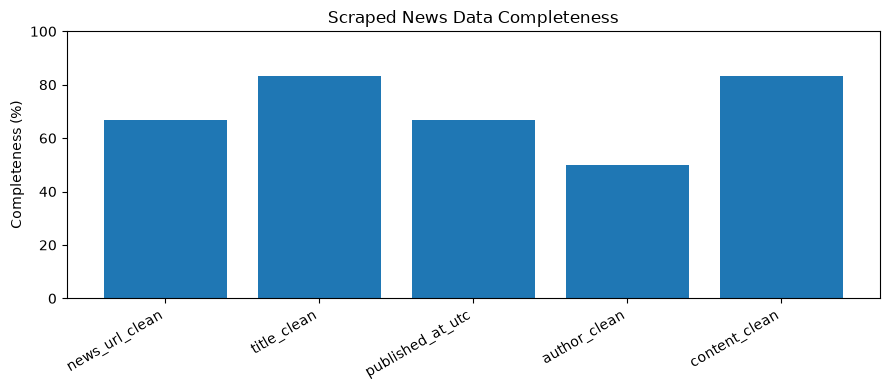

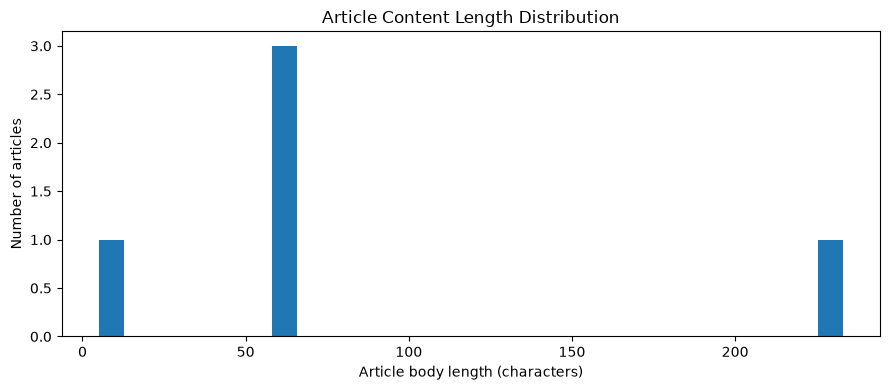

In [16]:
import matplotlib.pyplot as plt

# Completeness chart
plt.figure(figsize=(9, 4))
plt.bar(quality_report["field"], quality_report["completeness_pct"])
plt.ylabel("Completeness (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30, ha="right")
plt.title("Scraped News Data Completeness")
plt.tight_layout()
plt.show()

# Body length distribution (exclude empty bodies)
lengths = df.loc[df["content_char_count"] > 0, "content_char_count"]
if len(lengths):
    plt.figure(figsize=(9, 4))
    plt.hist(lengths, bins=30)
    plt.xlabel("Article body length (characters)")
    plt.ylabel("Number of articles")
    plt.title("Article Content Length Distribution")
    plt.tight_layout()
    plt.show()
else:
    print("No non-empty article bodies to plot.")


## 16. Advanced: source-level quality comparison

Scrapers often work well on some domains and poorly on others. Compare article counts, missing body rates, and short-content rates by domain. This is useful for deciding which extraction selectors or parsers need improvement.

Be careful when comparing small samples: a domain with two records can show 50% missing content from only one failure.

In [17]:
source_quality = (
    df.assign(
        content_missing=df["content_clean"].isna(),
        content_short=df["content_too_short"],
        time_missing=df["published_at_utc"].isna()
    )
    .groupby("domain", dropna=False)
    .agg(
        article_rows=("news_url_clean", "size"),
        missing_content_rate=("content_missing", "mean"),
        short_content_rate=("content_short", "mean"),
        missing_time_rate=("time_missing", "mean"),
        median_content_chars=("content_char_count", "median")
    )
    .reset_index()
)
for col in ["missing_content_rate", "short_content_rate", "missing_time_rate"]:
    source_quality[col] = (source_quality[col] * 100).round(2)

display(source_quality.sort_values(["missing_content_rate", "article_rows"], ascending=[False, False]))

,domain,article_rows,missing_content_rate,short_content_rate,missing_time_rate,median_content_chars
1,example.net,1,100.0,100.0,100.0,0.0
0,example.com,2,0.0,100.0,0.0,60.0
3,NaN,2,0.0,50.0,50.0,119.0
2,news.example.org,1,0.0,100.0,0.0,59.0


## 17. Optional: near-duplicate detection with TF-IDF

Exact matching misses stories whose titles differ slightly. Near-duplicate detection is a separate, more advanced step. This optional example uses TF-IDF title vectors and cosine similarity. It is most useful on a manageable sample; pairwise comparisons can become expensive for very large datasets.

Install scikit-learn if needed. Treat similarity as a candidate signal, not an automatic deletion rule. Two articles about the same event may be legitimately different reporting.

In [18]:
# Optional dependency:
# %pip install scikit-learn

# Uncomment to run:
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.metrics.pairwise import cosine_similarity
#
# titles = clean_df["title_clean"].fillna("").tolist()
# if 1 < len(titles) <= 3000:
#     X = TfidfVectorizer(ngram_range=(1, 2), min_df=1).fit_transform(titles)
#     sim = cosine_similarity(X, dense_output=False)
#     pairs = []
#     coo = sim.tocoo()
#     for i, j, score in zip(coo.row, coo.col, coo.data):
#         if i < j and score >= 0.90:
#             pairs.append({
#                 "row_i": int(i), "row_j": int(j), "similarity": round(float(score), 3),
#                 "title_i": titles[i], "title_j": titles[j]
#             })
#     # Passing columns= keeps this working even when no pair reaches the threshold.
#     near_duplicates = pd.DataFrame(
#         pairs, columns=["row_i", "row_j", "similarity", "title_i", "title_j"]
#     ).sort_values("similarity", ascending=False)
#     display(near_duplicates.head(50))
# else:
#     print("Use a sample or blocking strategy for large datasets.")


## 18. Production checklist

Before using the processed data for embeddings, feature engineering, clustering, or supervised learning, verify:

- [ ] Input filename, collection date, and scraper version are recorded.
- [ ] Raw data is retained and never overwritten.
- [ ] Column mapping was checked against the actual schema.
- [ ] URL normalization policy is documented.
- [ ] Timestamp timezone assumptions are documented and validated.
- [ ] HTML and whitespace cleaning has been visually reviewed.
- [ ] Missing author/time fields are not incorrectly treated as fatal.
- [ ] Duplicate policy is aligned with whether repeated story updates matter.
- [ ] Quality metrics are compared across domains and scraping runs.
- [ ] Rejected and review records are saved with reason flags.
- [ ] Output row counts reconcile with input counts.
- [ ] Train/test split strategy prevents leakage (for example, time-based split for future-news prediction).
- [ ] If the task is prediction, preprocessing choices were developed using training data only where they learn from data.

### Suggested next lessons
1. Data validation and quality assessment at scale.
2. PostgreSQL schema design and bulk insertion.
3. Text normalization, tokenization, and language detection.
4. Text embeddings and embedding quality checks.
5. Feature engineering from news title, body, author, domain, and publication time.
6. Train/test splitting for time-dependent news data.

### Final exercise
Use your own scraped news CSV and submit:
1. A short raw-data profiling report.
2. A documented preprocessing policy.
3. Clean, review, and rejected CSV files.
4. A quality report by field and by domain.
5. Five examples showing a raw record and its cleaned version.
6. A short explanation of which rules are universal and which depend on the downstream task.